<a href="https://colab.research.google.com/github/ManuelSena25/Dental-Lesion-Detection/blob/main/07_Final_Model_Comparison_Simplified.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Final Model Comparison
**Dental Lesion Classification in Panoramic X-rays**

Comparison of nine classification experiments and one object detection model.

In [1]:
#Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from google.colab import drive
import seaborn as sns
from IPython.display import Image, display

#Connect Google Drive
drive.mount("/content/drive")

#Define project folders
PROJECT_DIR = Path("/content/drive/MyDrive/Dental_Lesion_Detection")
RESULTS_DIR = PROJECT_DIR / "results"

Mounted at /content/drive


### Classification results
Compare accuracy and macro F1 on the test set. Macro F1 gives equal importance to each class.

In [2]:
#Load traditional machine learning results
traditional_val = pd.read_csv(
    RESULTS_DIR / "traditional_ml_results.csv"
)

traditional_test = pd.read_csv(
    RESULTS_DIR / "traditional_ml_test_comparison.csv"
)

#Load deep learning results
deep_val = pd.read_csv(
    RESULTS_DIR / "deep_learning_validation_verified.csv"
)

deep_test = pd.read_csv(
    RESULTS_DIR / "deep_learning_test_comparison.csv"
)

#Load YOLO11 results
yolo_test = pd.read_csv(
    RESULTS_DIR / "yolo11_test_results.csv"
)

#Rename traditional ML columns
traditional_test = traditional_test.rename(columns={
    "Precision": "Macro Precision",
    "Recall": "Macro Recall",
    "F1-score": "Macro F1"
})

#Identify model categories
traditional_test["Category"] = "Traditional ML"
deep_test["Category"] = "Deep Learning"

#Combine test results
final_results = pd.concat(
    [traditional_test, deep_test],
    ignore_index=True
)

#Sort models by accuracy
final_results = final_results.sort_values(
    "Accuracy", ascending=False
)

final_results = final_results.reset_index(drop=True)

#Save final results
final_results.to_csv(
    RESULTS_DIR / "final_classification_results.csv",
    index=False
)

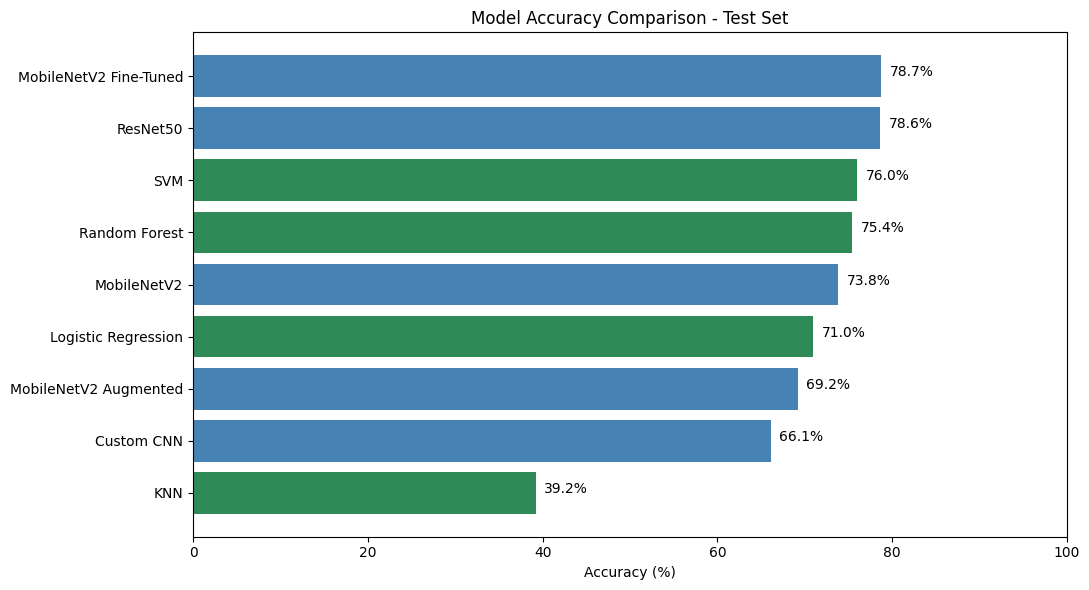

In [3]:
#Assign colors to each model
colors = final_results["Category"].map({"Deep Learning": "steelblue", "Traditional ML": "seagreen"})

#Plot accuracy comparison
plt.figure(figsize=(11, 6))

plt.barh(
    final_results["Model"],
    final_results["Accuracy"] * 100,
    color=colors
)

#Display accuracy values
for i, value in enumerate(final_results["Accuracy"]):
    plt.text(value * 100 + 1, i, f"{value * 100:.1f}%")

plt.gca().invert_yaxis()

plt.title("Model Accuracy Comparison - Test Set")
plt.xlabel("Accuracy (%)")
plt.xlim(0, 100)
plt.tight_layout()

#Save figure
plt.savefig(
    RESULTS_DIR / "final_accuracy_comparison.png",
    dpi=300
)

plt.show()

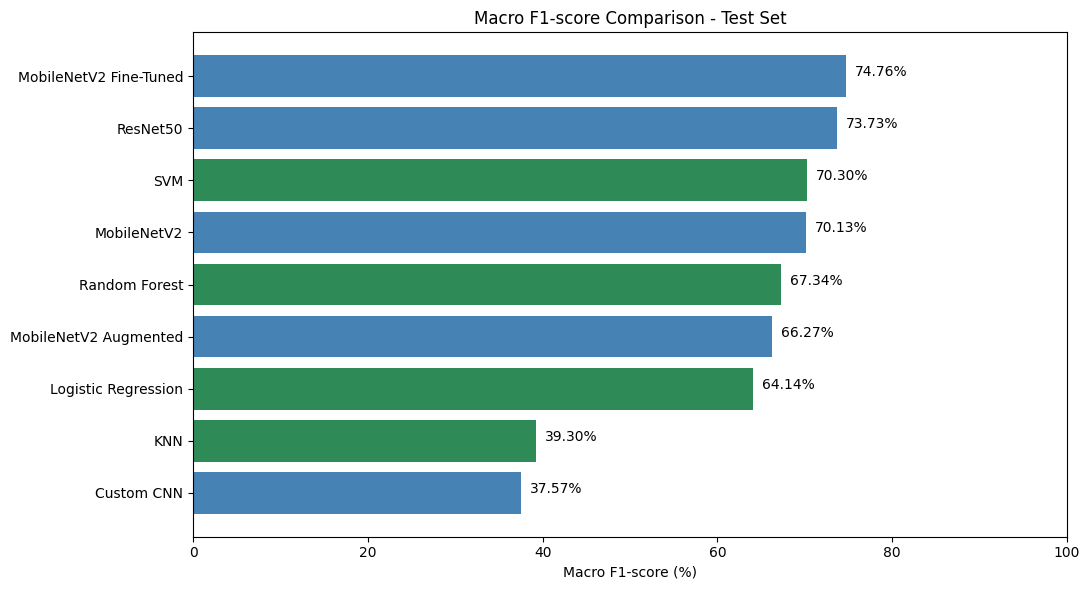

In [4]:
#Sort models by macro F1-score
f1_results = final_results.sort_values(
    "Macro F1", ascending=False
)

#Assign colors
colors = f1_results["Category"].map({"Deep Learning": "steelblue", "Traditional ML": "seagreen"})

#Plot F1-score comparison
plt.figure(figsize=(11, 6))

plt.barh(
    f1_results["Model"],
    f1_results["Macro F1"] * 100,
    color=colors
)

#Display F1-score values
for i, value in enumerate(f1_results["Macro F1"]):
    plt.text(value * 100 + 1, i, f"{value * 100:.2f}%")

plt.gca().invert_yaxis()

plt.title("Macro F1-score Comparison - Test Set")
plt.xlabel("Macro F1-score (%)")
plt.xlim(0, 100)
plt.tight_layout()

#Save figure
plt.savefig(
    RESULTS_DIR / "final_f1_comparison.png",
    dpi=300
)

plt.show()

Fine-Tuned MobileNetV2 obtained the highest test accuracy (78.7%) and macro F1 (74.8%). SVM was the strongest traditional classifier. Custom CNN achieved 66.1% accuracy but only 37.6% macro F1, showing why accuracy alone is insufficient.

## Validation vs. test




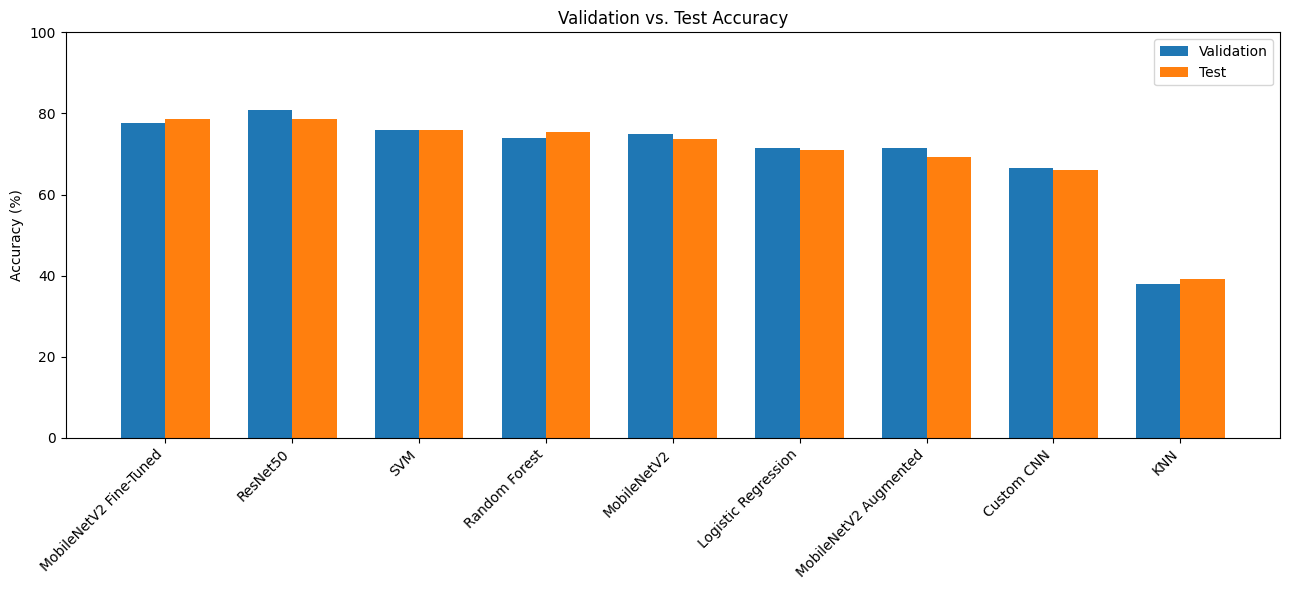

In [5]:
#Select validation metrics
validation_results = pd.concat([
    traditional_val[["Model", "Accuracy", "Macro F1"]],
    deep_val[["Model", "Accuracy", "Macro F1"]]
], ignore_index=True)

#Select test metrics
test_results = final_results[
    ["Model", "Accuracy", "Macro F1"]
]

#Combine validation and test results
comparison = pd.merge(
    validation_results,
    test_results,
    on="Model",
    suffixes=("_Val", "_Test")
)

#Sort results
comparison = comparison.sort_values(
    "Accuracy_Test", ascending=False
)

#Calculate performance differences
comparison["Accuracy Difference"] = (
    comparison["Accuracy_Test"] -
    comparison["Accuracy_Val"]
)

comparison["F1 Difference"] = (
    comparison["Macro F1_Test"] -
    comparison["Macro F1_Val"]
)

#Save comparison
comparison.to_csv(
    RESULTS_DIR / "final_validation_test_comparison.csv",
    index=False
)

#Define bar positions
x = np.arange(len(comparison))
width = 0.35

#Plot validation and test accuracy
plt.figure(figsize=(13, 6))

plt.bar(
    x - width / 2,
    comparison["Accuracy_Val"] * 100,
    width,
    label="Validation"
)

plt.bar(
    x + width / 2,
    comparison["Accuracy_Test"] * 100,
    width,
    label="Test"
)

plt.xticks(x, comparison["Model"], rotation=45, ha="right")
plt.ylabel("Accuracy (%)")
plt.title("Validation vs. Test Accuracy")
plt.ylim(0, 100)
plt.legend()
plt.tight_layout()

#Save figure
plt.savefig(
    RESULTS_DIR / "final_validation_test_accuracy.png",
    dpi=300
)

plt.show()

ResNet50 achieved the highest validation accuracy (80.8%) and macro F1 (75.1%), making it the validation-selected classifier. Fine-Tuned MobileNetV2 achieved slightly higher test accuracy; this small difference does not establish statistical superiority.

## Per-class performance
The test set contains 628 PAI 3, 269 PAI 4 and 103 PAI 5 samples. The following heatmaps compare the five deep learning experiments.

In [6]:
#Load the saved classification reports
files = {
    "Custom CNN": "custom_cnn_test_report.csv",
    "MobileNetV2": "mobilenet_v2_test_report.csv",
    "MobileNetV2 Fine-Tuned": "mobilenet_v2_finetuned_test_report.csv",
    "MobileNetV2 Augmented": "mobilenet_v2_augmented_test_report.csv",
    "ResNet50": "resnet50_classification_report.csv"
}

#Keep only the three lesion classes
class_results = []
for model, file in files.items():
    report = pd.read_csv(RESULTS_DIR / file, index_col=0)
    report = report.loc[["PAI 3", "PAI 4", "PAI 5"]].copy()
    report["Model"] = model
    report["Class"] = report.index
    class_results.append(report)

class_results = pd.concat(class_results, ignore_index=True)
class_results = class_results[["Model", "Class", "precision", "recall", "f1-score", "support"]]
class_results.to_csv(RESULTS_DIR / "deep_learning_per_class_results.csv", index=False)

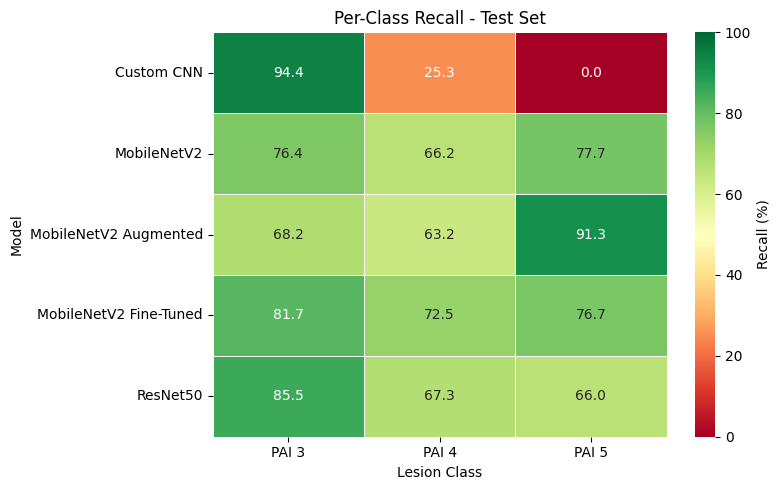

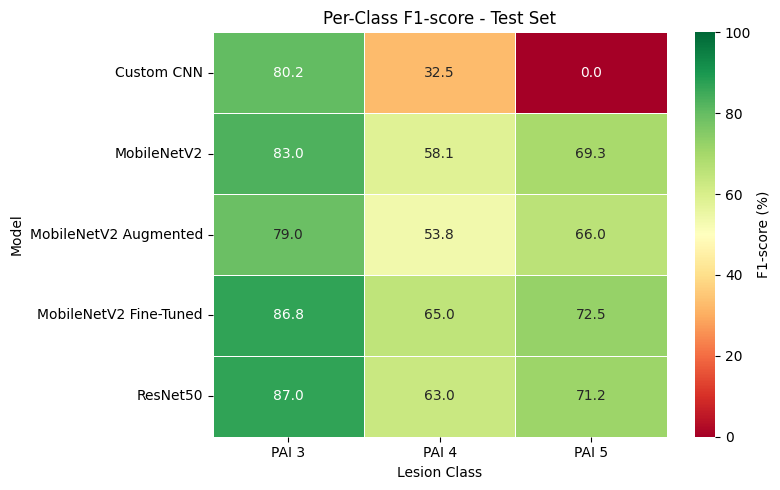

In [7]:
#Plot recall and F1-score by class
for metric, name, filename in [
    ("recall", "Recall", "per_class_recall_heatmap.png"),
    ("f1-score", "F1-score", "per_class_f1_heatmap.png")
]:
    table = class_results.pivot(index="Model", columns="Class", values=metric)
    plt.figure(figsize=(8, 5))
    sns.heatmap(table * 100, annot=True, fmt=".1f", cmap="RdYlGn",
                vmin=0, vmax=100, linewidths=0.5,
                cbar_kws={"label": name + " (%)"})
    plt.title("Per-Class " + name + " - Test Set")
    plt.xlabel("Lesion Class")
    plt.ylabel("Model")
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / filename, dpi=300)
    plt.show()

Custom CNN failed to identify any PAI 5 samples. Augmented MobileNetV2 increased PAI 5 recall from 77.7% to 91.3%, but its F1-score decreased from 69.3% to 66.0%. Fine-Tuned MobileNetV2 achieved the highest F1-score for PAI 4 and PAI 5 among the deep learning experiments. These results illustrate the trade-off between minority-class recall and precision.

## Confusion matrices

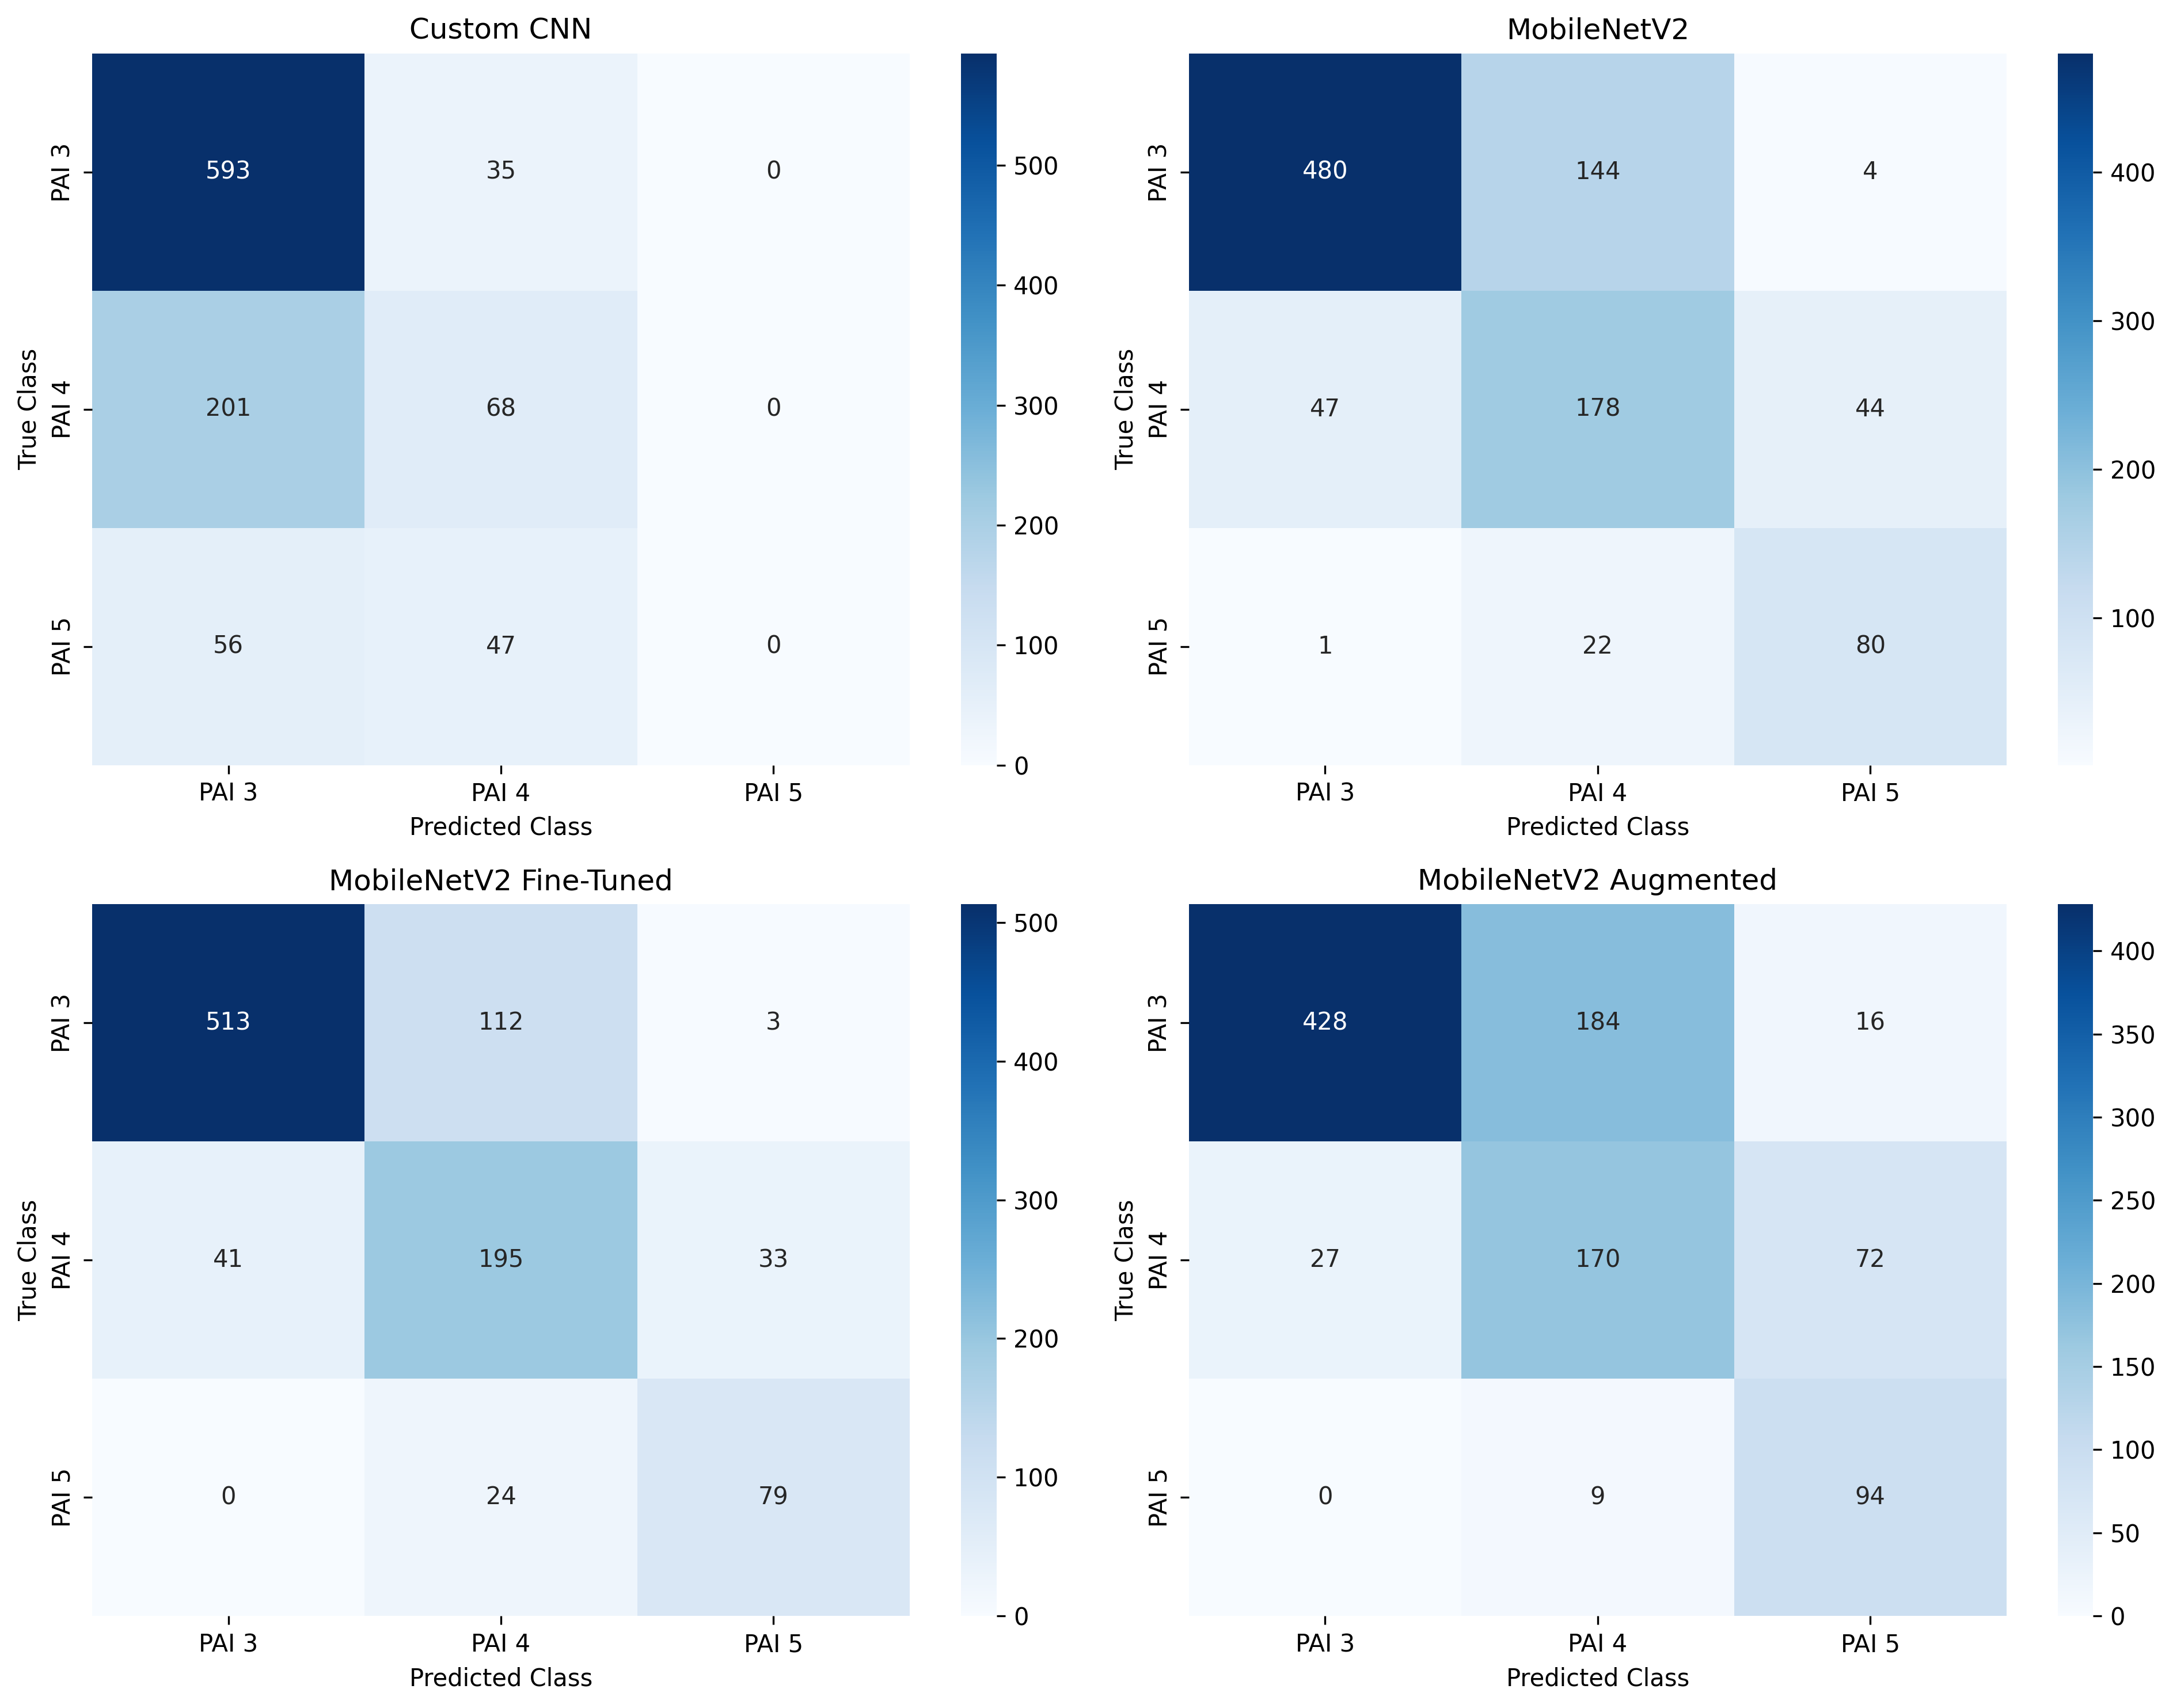

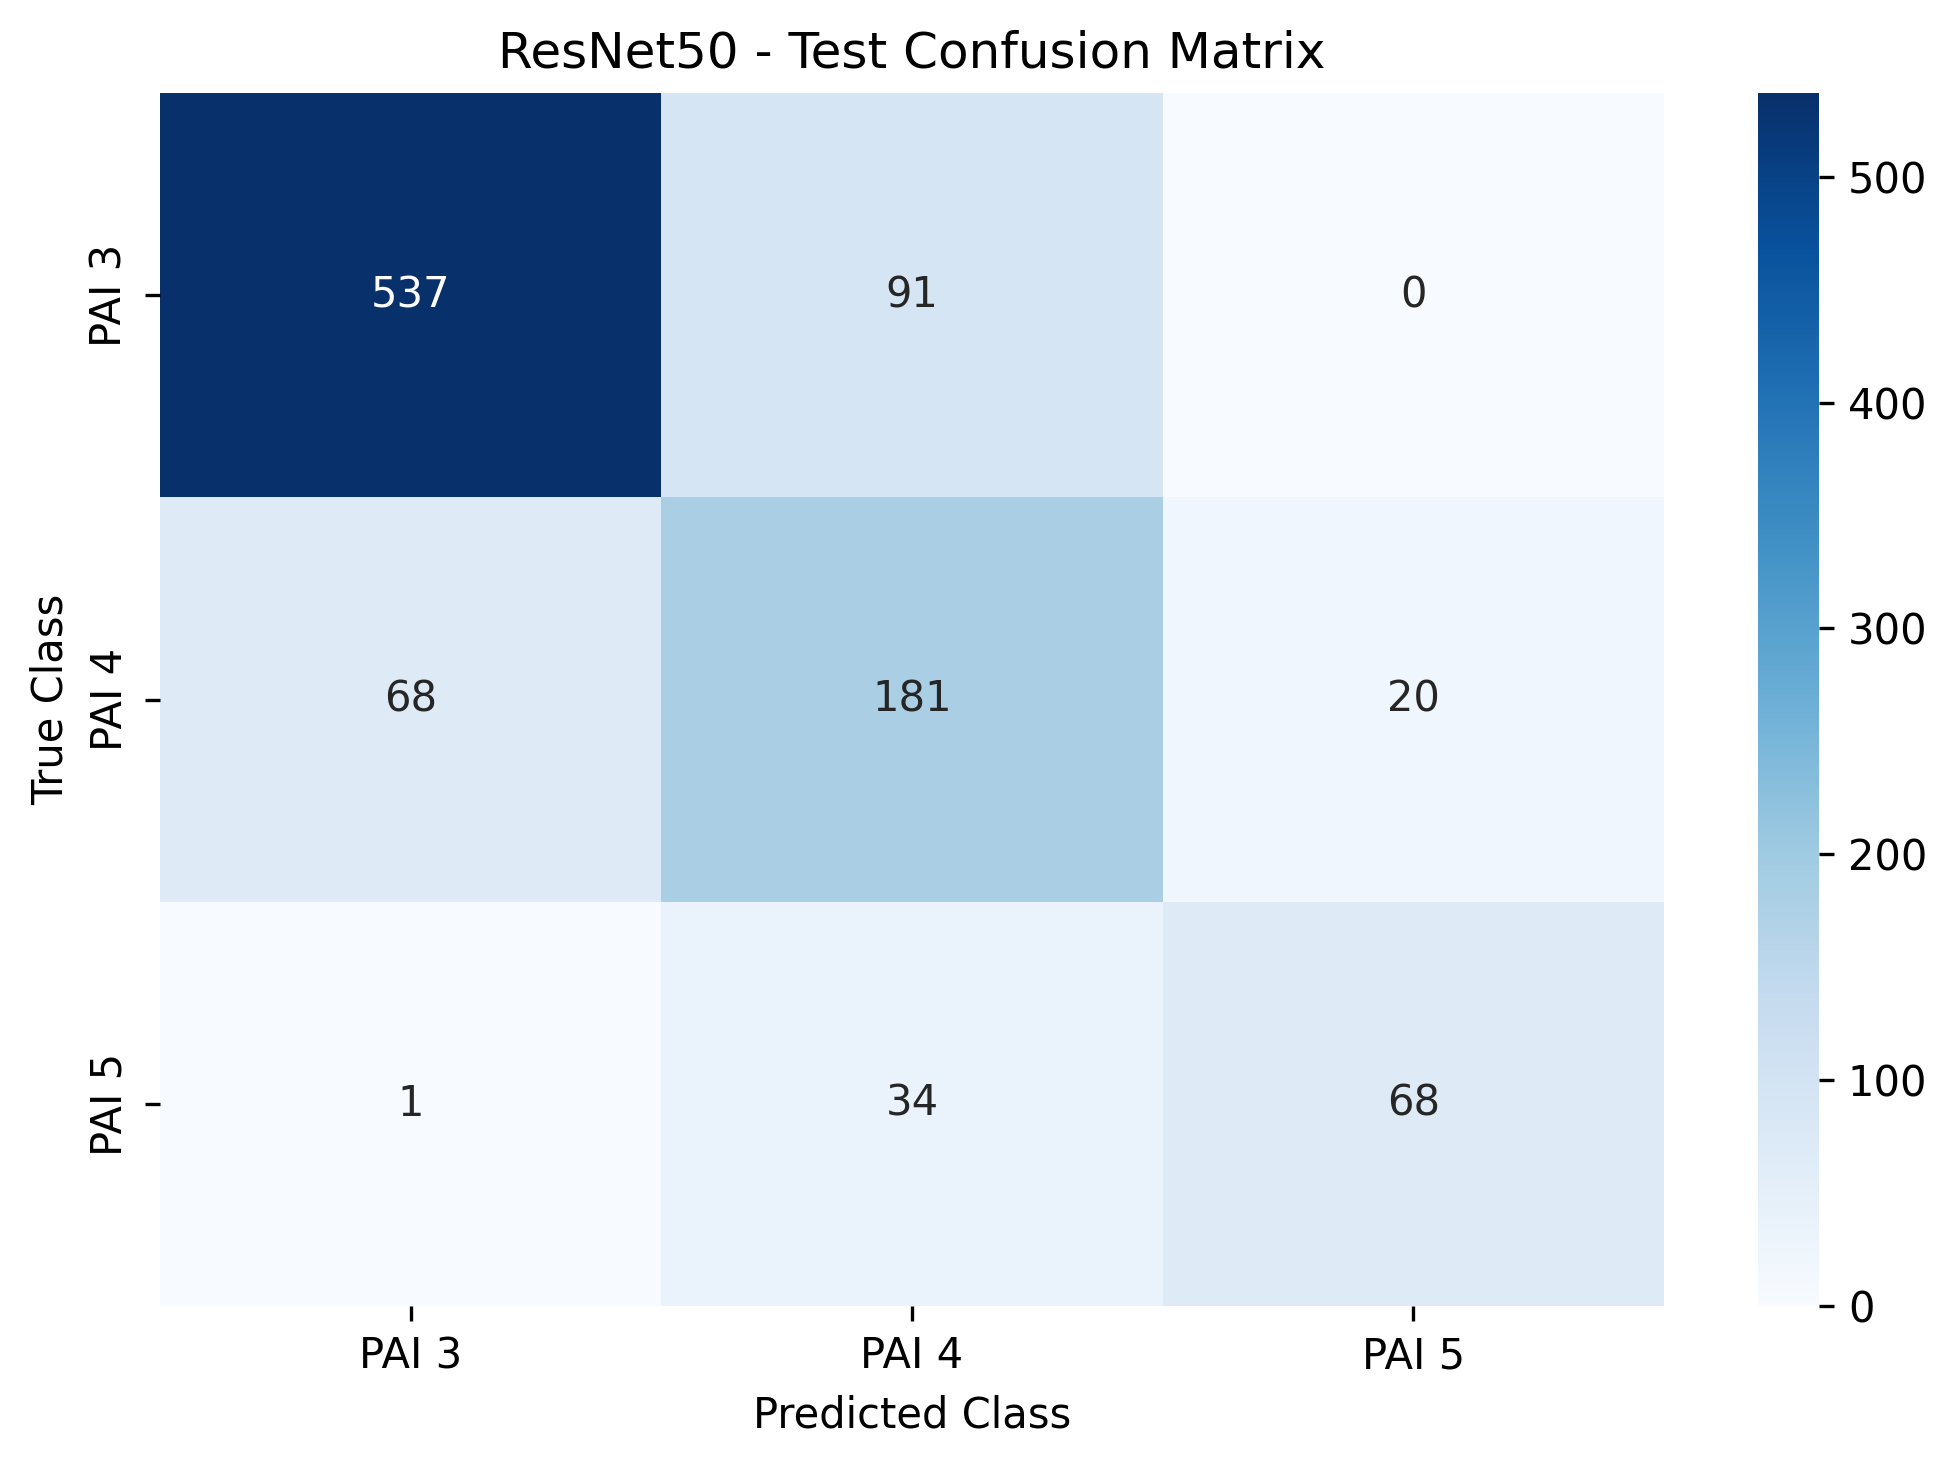

In [8]:
#Display previously saved confusion matrices
for file in ["cnn_test_confusion_matrices.png", "resnet50_test_confusion_matrix.png"]:
    display(Image(filename=str(RESULTS_DIR / file)))

Most errors occurred between adjacent severity classes, especially PAI 3 and PAI 4. Custom CNN predicted 56 PAI 5 samples as PAI 3, while ResNet50 made only one error between these two classes out of 214 incorrect predictions. Class imbalance and visual similarities may contribute to these errors, but their individual effects were not established.

## YOLO11 detection results
Detection is evaluated separately because it must locate and classify lesions in full radiographs, rather than classify annotated crops.

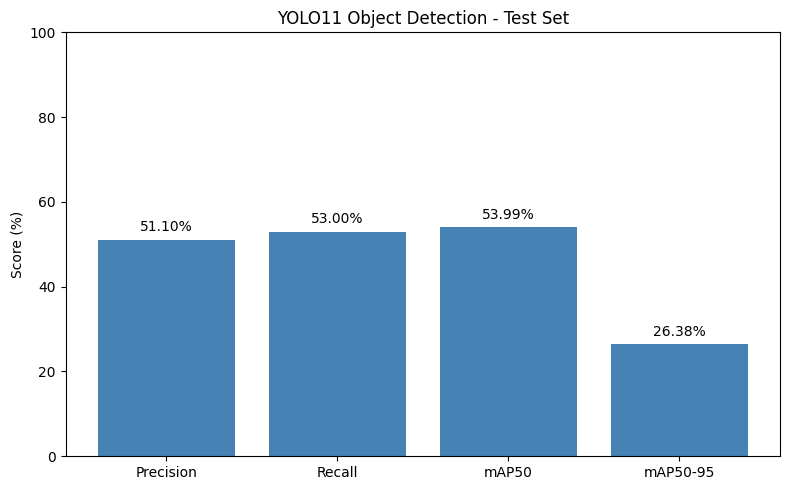

In [9]:
#Select object detection metrics
metrics = ["Precision", "Recall", "mAP50", "mAP50-95"]

values = yolo_test.loc[0, metrics].astype(float) * 100

#Plot detection results
plt.figure(figsize=(8, 5))

plt.bar(metrics, values, color="steelblue")

#Display metric values
for i, value in enumerate(values):
    plt.text(i, value + 2, f"{value:.2f}%", ha="center")

plt.title("YOLO11 Object Detection - Test Set")
plt.ylabel("Score (%)")
plt.ylim(0, 100)
plt.tight_layout()

#Save figure
plt.savefig(
    RESULTS_DIR / "final_yolo11_comparison.png",
    dpi=300
)

plt.show()

YOLO11 achieved 54.0% mAP50, 26.4% mAP50-95, 51.1% precision and 53.0% recall on 582 test radiographs. These results indicate limitations in detection and localization.

### Detection error examples
Compare the saved ground-truth and prediction images below. Specific missed lesions and false detections must be identified by inspecting the paired images before writing the final discussion.

val_batch0_labels.jpg


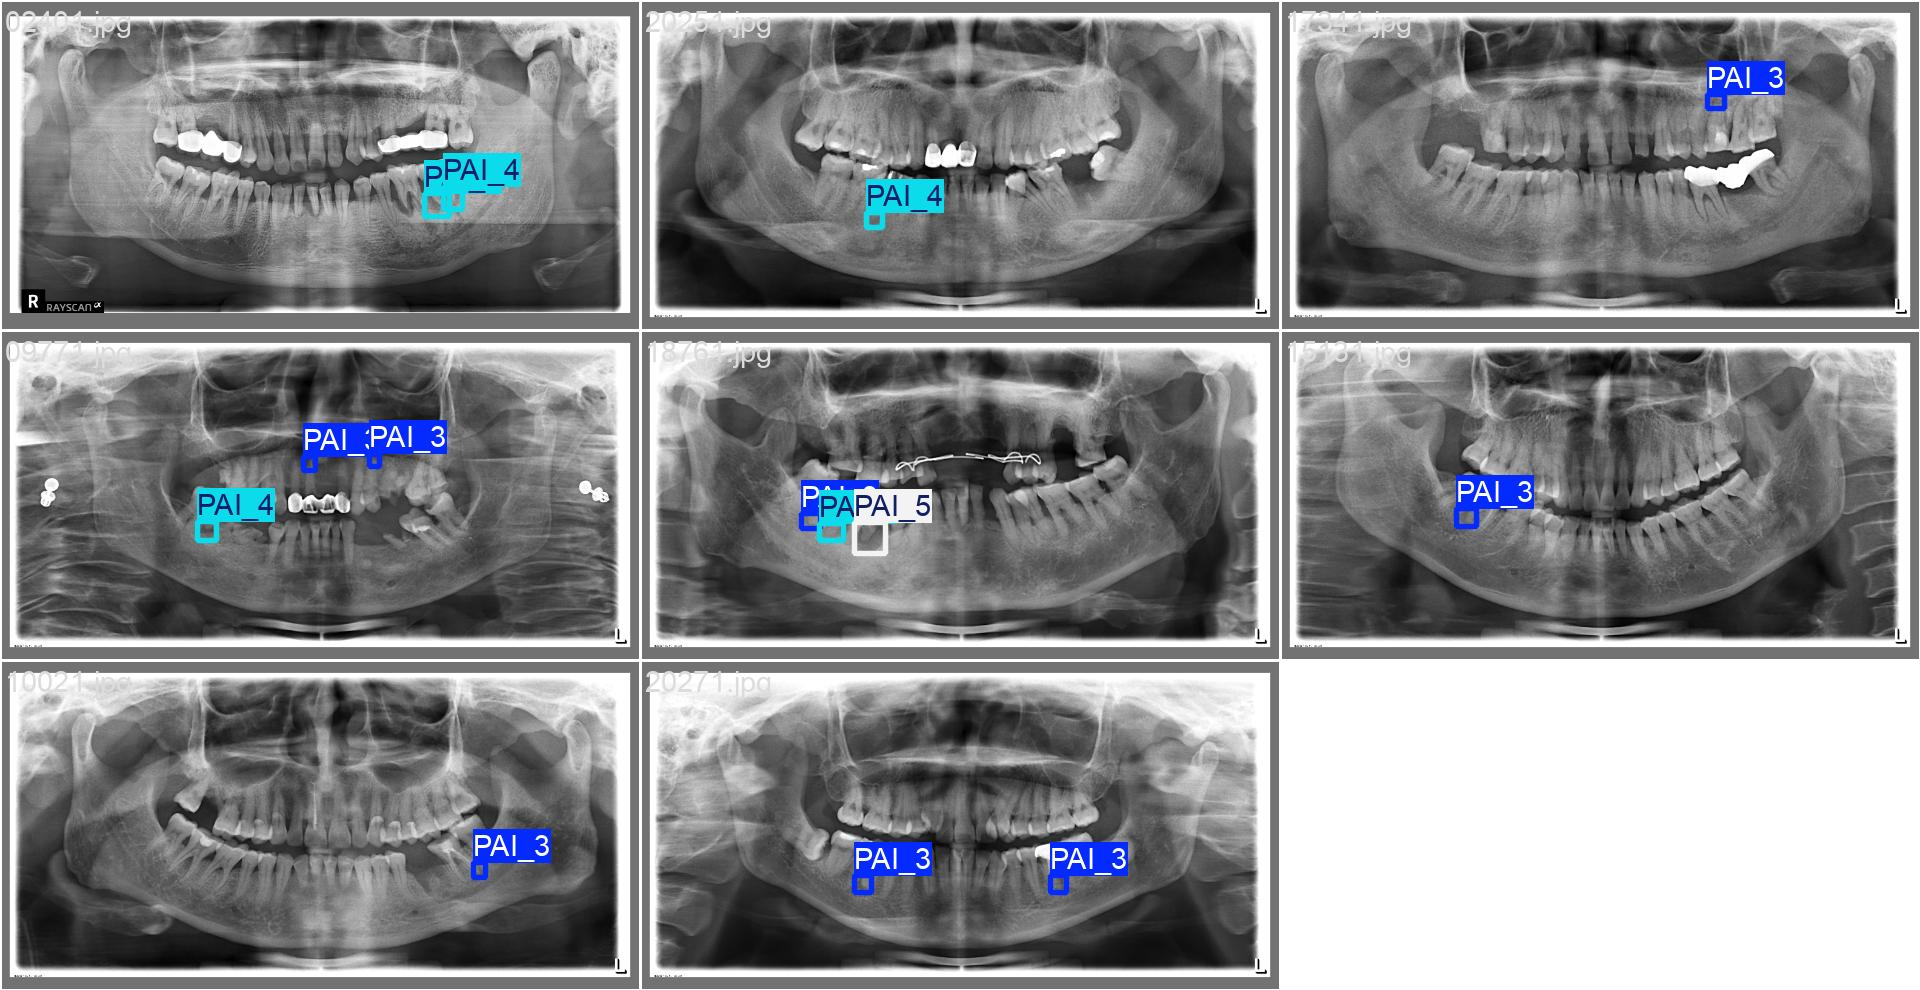

val_batch0_pred.jpg


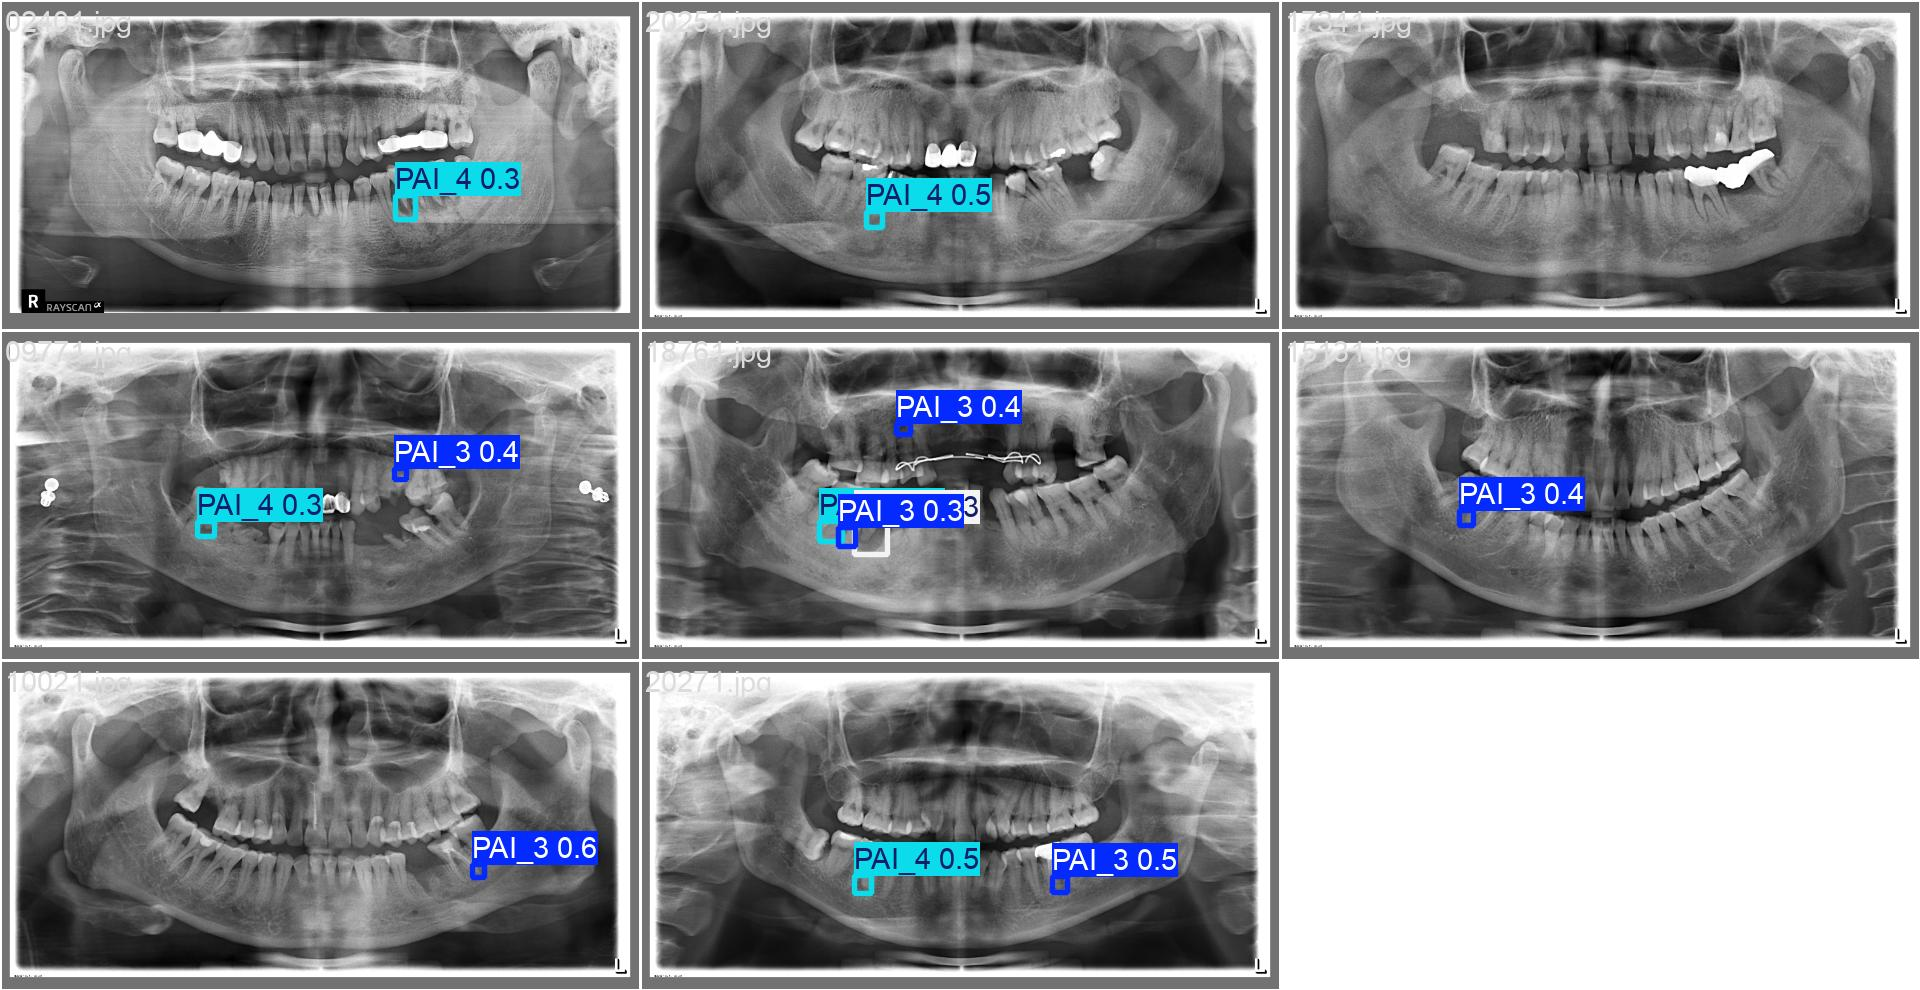

In [10]:
#Display saved YOLO evaluation examples, if available
YOLO_TEST_DIR = PROJECT_DIR / "models" / "yolo11_detection" / "final_test"

for file in ["val_batch0_labels.jpg", "val_batch0_pred.jpg"]:
    path = YOLO_TEST_DIR / file
    if path.exists():
        print(file)
        display(Image(filename=str(path)))
    else:
        print("Not found:", file)

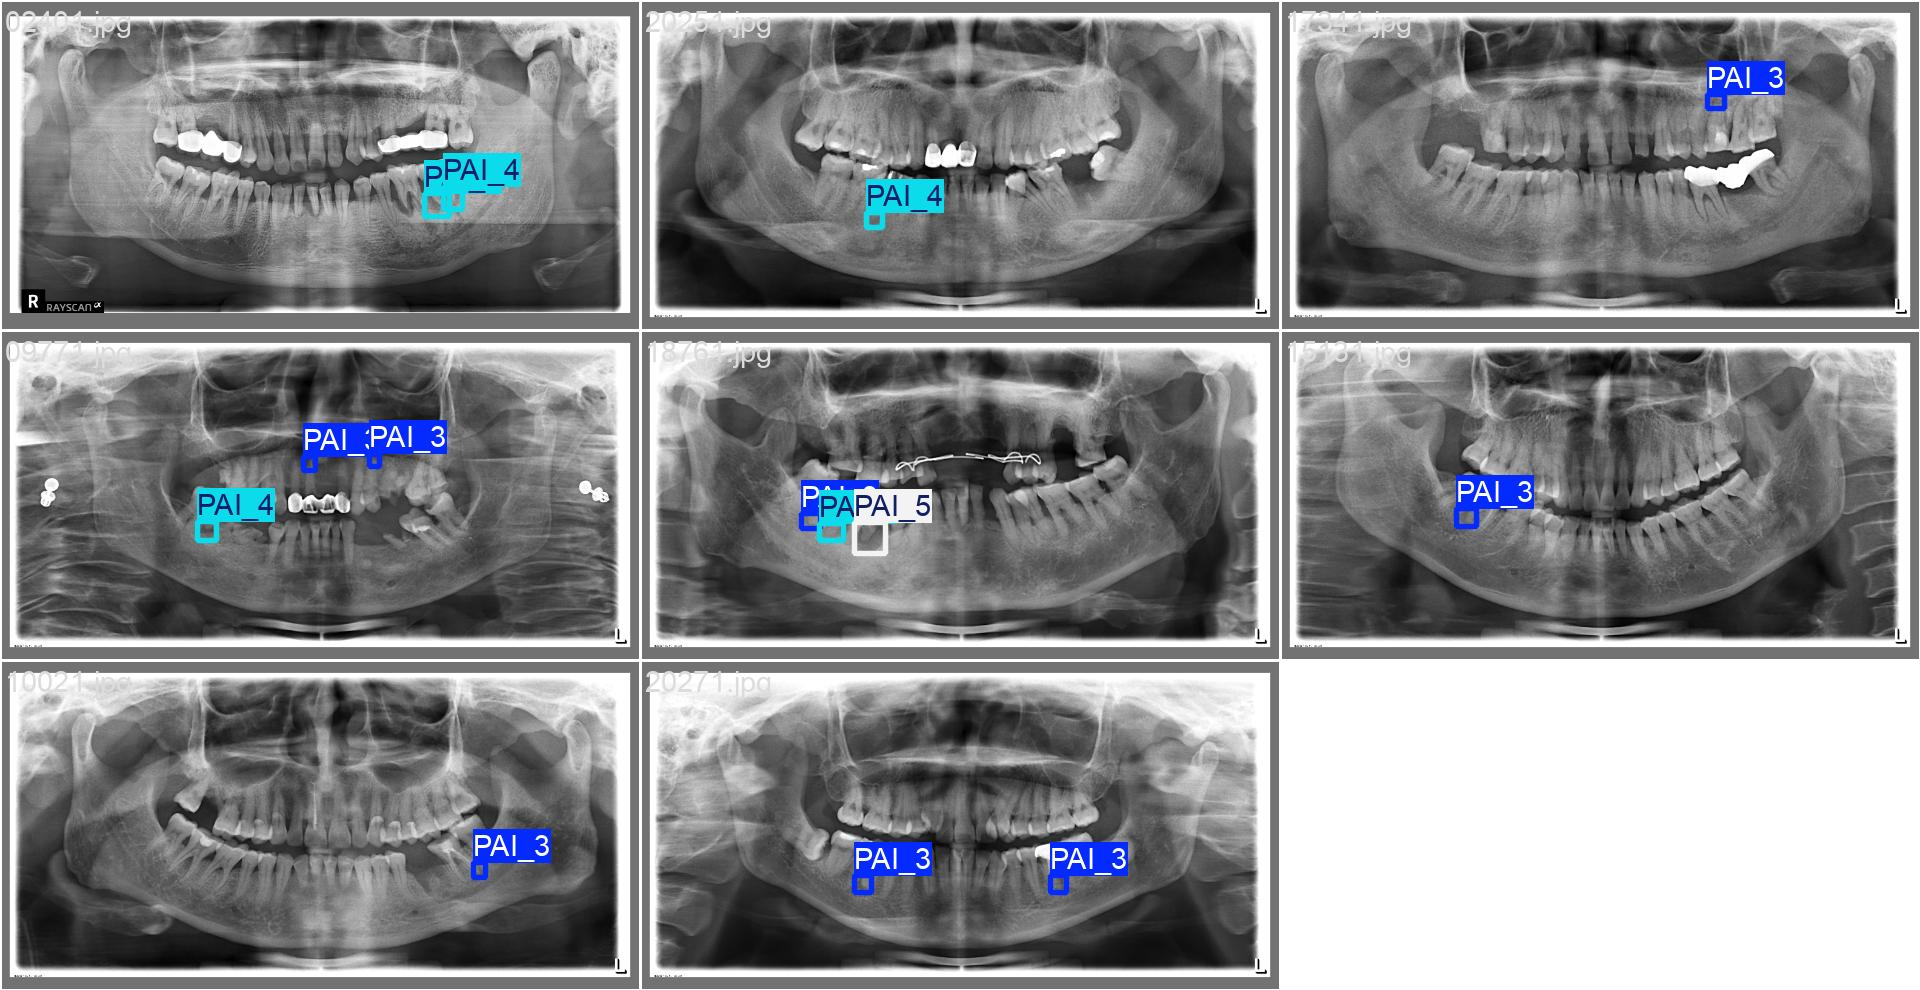

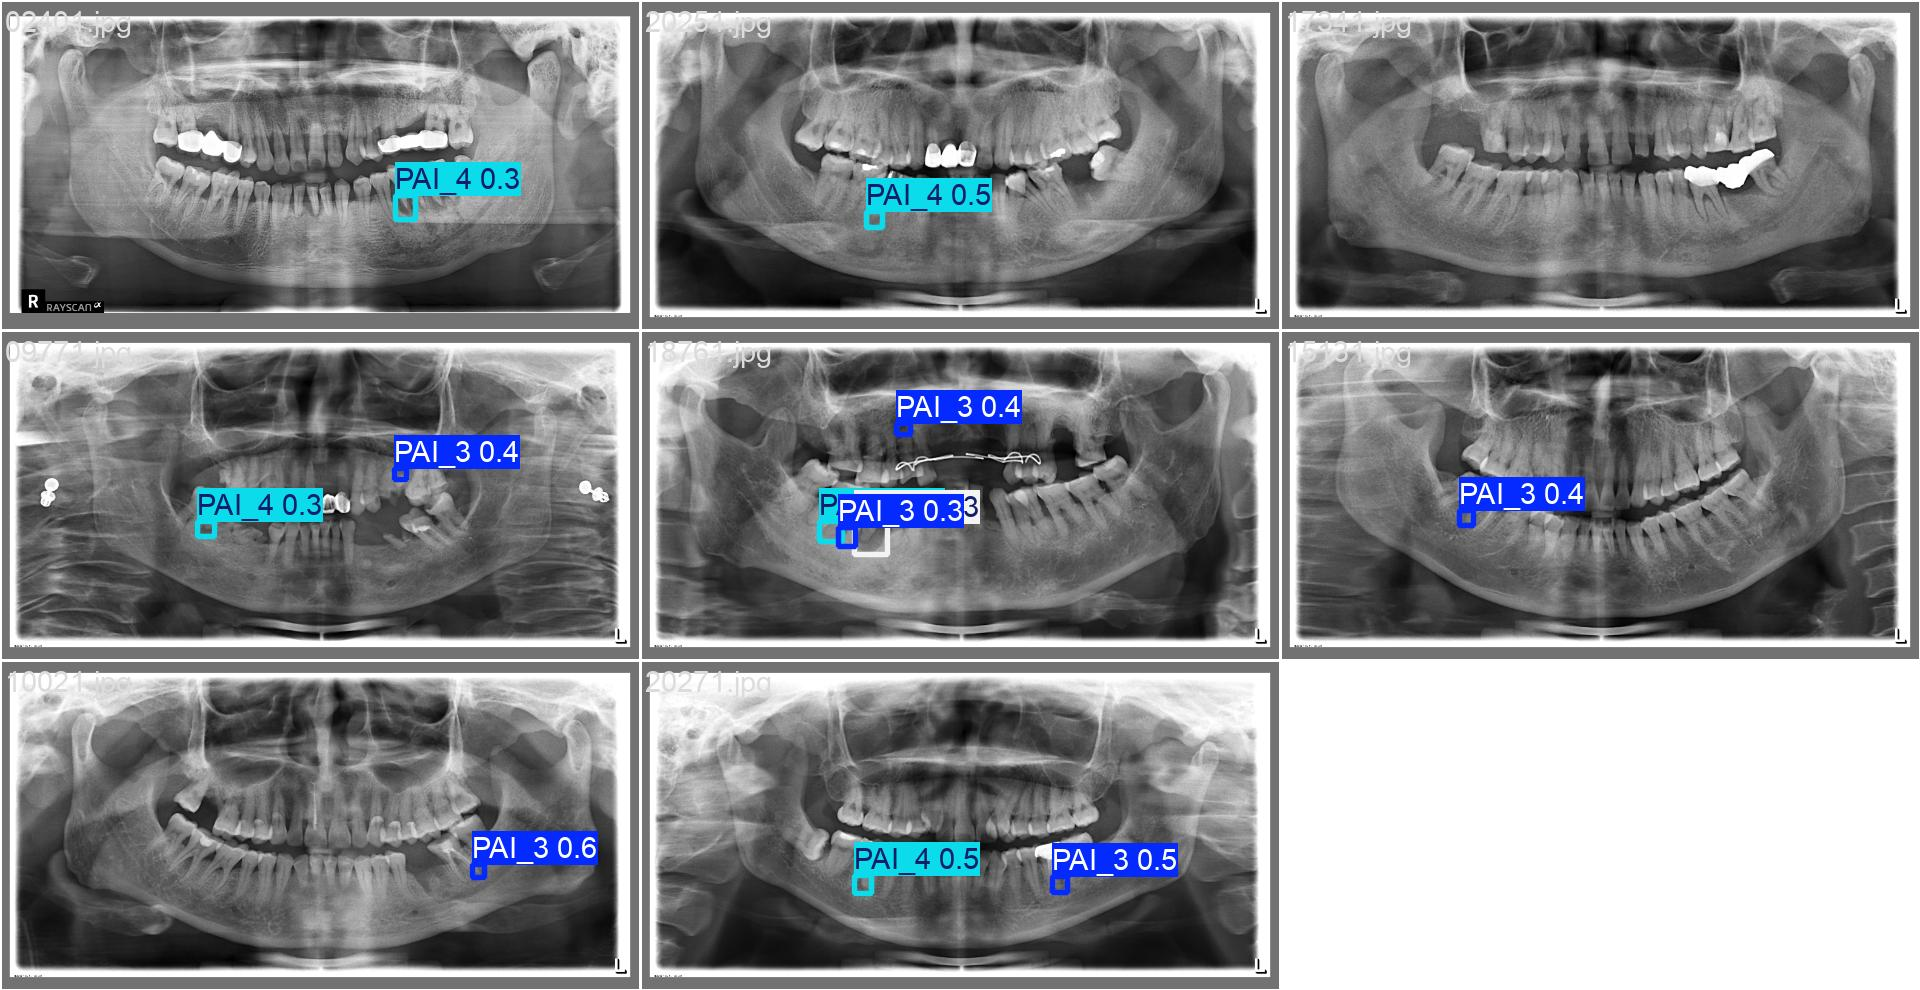

In [11]:
from IPython.display import Image, display

#YOLO test results folder
YOLO_TEST_DIR = PROJECT_DIR / "models/yolo11_detection/final_test"

#Display original annotations
display(Image(filename=str(
    YOLO_TEST_DIR / "val_batch0_labels.jpg"
)))

#Display model predictions
display(Image(filename=str(
    YOLO_TEST_DIR / "val_batch0_pred.jpg"
)))

##YOLO11 Detection Error Analysis

The comparison between ground truth annotations and YOLO11 predictions reveals both successful detections and localization difficulties.

In some cases, the model correctly identified the location and severity class of annotated lesions. However, other lesions were missed, and some predicted regions did not appear to correspond to the original annotations.

Several detections also presented relatively low confidence scores, ranging approximately from 0.3 to 0.5 in the displayed examples.